# 03 · Características de las retinografías locales

**Pregunta:** ¿Cómo varían el brillo, el color, la nitidez y el encuadre entre las distintas bases locales y después de su procesamiento?

Referencia de arquitectura y partición previa: [Comprobacion_mejor_modelo.ipynb](../02_experimento_seleccion_datasets_y_modelos/Comprobacion_mejor_modelo.ipynb).

## 1. Configuración e inventario de fuentes

Se cargan las tablas precalculadas en `03_experimento_caracteristicas_retinografias/datos/` junto con el dataset auditado (`utilidades/dataset_auditado.csv`).

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

_root = Path.cwd().resolve()
if not (_root / "utilidades/utilidades.py").is_file() and (_root.parent / "utilidades/utilidades.py").is_file():
    _root = _root.parent
sys.path.insert(0, str(_root / "utilidades"))
sys.path.insert(0, str(_root / "03_experimento_caracteristicas_retinografias/scripts"))

import utilidades as u
from metricas_retinografias import measure
from procedencia_retinografias import pair_candidates, verify_pair

ROOT = u.obtener_raiz()
HIST = ROOT / "03_experimento_caracteristicas_retinografias/datos"
SCRIPTS = ROOT / "03_experimento_caracteristicas_retinografias/scripts"
SALIDAS = ROOT / "03_experimento_caracteristicas_retinografias/datos"

hrows = pd.read_csv(HIST / "por_imagen.csv", low_memory=False)
pares = pd.read_csv(HIST / "pares.csv", low_memory=False)
df_auditado, _ = u.cargar_dataset(ROOT)

FEATURES = {
    "brillo_mediano_yn": "Brillo mediano (luma, 0–255)",
    "contraste_de_yn": "Contraste (DE de luma)",
    "r_media": "Rojo medio (0–255)",
    "g_media": "Verde medio (0–255)",
    "b_media": "Azul medio (0–255)",
    "saturacion_media_pct": "Saturación (%)",
    "ancho_px": "Ancho (px)",
    "alto_px": "Alto (px)",
    "laplaciano_nativo": "Laplaciano (nativo)",
    "laplaciano_lado512": "Laplaciano (lado 512 px)",
    "negro_pct": "Píxeles casi negros (%)",
    "negro_borde_pct": "Casi negro en borde (%)",
    "region_pct": "Área retiniana visible (%)",
    "centro_x": "Centro X",
    "centro_y": "Centro Y",
    "extension_x": "Extensión horizontal",
    "extension_y": "Extensión vertical",
}

def tabla_percentiles(df, grupo, metricas):
    m = df.melt(id_vars=grupo, value_vars=list(metricas), var_name="medida", value_name="valor")
    out = m.groupby(grupo + ["medida"], dropna=False, sort=False)["valor"].agg(
        n="size", validos="count", p25=lambda s: s.quantile(0.25), mediana="median", p75=lambda s: s.quantile(0.75)
    ).reset_index()
    out["RIC"] = out["p75"] - out["p25"]
    return out

resumen_fuentes = pd.DataFrame({
    "n_inventario": hrows["coleccion"].value_counts(),
    "n_elegible_experimentos": df_auditado["coleccion"].value_counts(),
}).fillna(0).astype(int)
display(resumen_fuentes)

,n_inventario,n_elegible_experimentos
coleccion,,
ACRIMA,705,703
EyePACS REAL,200,200
EyePACS TRAIN,200,0
Megacohorte,2937,0
Moondream Staged,800,706
RIM-ONE DL,447,447
THIRD_DATASET,2805,0
Web emulada,148,0


## 2. Verificación puntual sobre los archivos locales

Recalculamos las métricas sobre una muestra estratificada de imágenes reales en disco y comprobamos los pares original ↔ derivada.

In [2]:
muestra = hrows[hrows["sha256_archivo"].notna()].groupby(["coleccion", "tipo"], sort=False).apply(
    lambda g: g.sample(n=min(5, len(g)), random_state=u.SEED), include_groups=False
).reset_index(level=[0, 1])

recalculo = []
for row in muestra.itertuples():
    ruta = ROOT / row.id_imagen
    med = measure(ruta, row.tipo)
    diffs = [abs(float(getattr(row, k)) - med[k]) for k in FEATURES if med.get(k) is not None and pd.notna(getattr(row, k))]
    recalculo.append({
        "fuente": row.coleccion, "ruta": row.id_imagen,
        "sha_ok": med["sha256_archivo"] == row.sha256_archivo,
        "max_diff": max(diffs, default=0.0),
    })

rep_verif = pd.DataFrame(recalculo)
rep_verif.to_csv(SALIDAS / "03_recalculo_verificacion.csv", index=False)
display(rep_verif.groupby("fuente").agg(n=("ruta", "size"), sha_ok=("sha_ok", "sum"), max_diff=("max_diff", "max")).round(6))

# Comprobación de pares original -> derivada
cfg = json.loads((SCRIPTS / "fuentes_retinografias.json").read_text(encoding="utf-8-sig"))
cands = pair_candidates([dict(r, path=ROOT / r["id_imagen"]) for r in hrows.to_dict("records")], cfg["fuentes"])
fuentes_idx = hrows.set_index("id_imagen")
muestra_pares = pares.groupby(["fuente", "transformacion"], sort=False).head(3)
pares_ok = []
for row in muestra_pares.itertuples():
    obs = dict(fuentes_idx.loc[row.id_derivada], id_imagen=row.id_derivada, path=ROOT / row.id_derivada)
    res = verify_pair(obs, cands.get(row.id_derivada))
    pares_ok.append({"fuente": row.fuente, "transformacion": row.transformacion, "coincide": res.get("id_original") == row.id_original})
display(pd.DataFrame(pares_ok).groupby(["fuente", "transformacion"])["coincide"].agg(["size", "sum"]))

,n,sha_ok,max_diff
fuente,,,
ACRIMA,5,5,0.000004
EyePACS REAL,5,5,0.000005
EyePACS TRAIN,5,5,0.000005
Megacohorte,5,5,0.000005
Moondream Staged,5,5,0.000004
RIM-ONE DL,5,5,0.000003
THIRD_DATASET,5,5,0.000000
Web emulada,10,10,0.000005


size  sum
fuente           transformacion           
ACRIMA           emular_web         3    3
                 escalar            3    3
EyePACS REAL     recortar_color     3    3
Moondream Staged escalar            3    3
RIM-ONE DL       escalar            3    3

## 3. Moondream original (800) vs. auditado sin cruces (706)

Comparamos el perfil de color global (RGB), brillo, área visible y relleno en esquinas entre las carpetas originales de Moondream y la versión limpia usada para entrenar y evaluar.

pad_negro        pad_gris       
                             size   mean     size   mean
version        clase                                    
Auditado (706) advanced       177  0.446      177  0.169
               early          163  0.491      163  0.196
               normal         366  0.527      366  0.142
Original (800) advanced       200  0.460      200  0.170
               early          200  0.485      200  0.200
               normal         400  0.507      400  0.148

,version,split,clase,medida,n,validos,p25,mediana,p75,RIC
30,Original (800),test,advanced,B,50,50,4.77,45.34,86.99,82.22
31,Original (800),test,early,B,50,50,5.74,32.75,106.02,100.28
32,Original (800),test,normal,B,100,100,6.96,63.21,102.43,95.47
33,Original (800),train,advanced,B,150,150,5.48,31.63,82.45,76.97
34,Original (800),train,early,B,150,150,5.62,34.16,99.46,93.84
35,Original (800),train,normal,B,300,300,23.06,72.37,113.08,90.02
36,Auditado (706),train,normal,B,264,264,13.84,65.60,102.43,88.58
37,Auditado (706),train,advanced,B,125,125,6.47,32.16,83.16,76.68
38,Auditado (706),train,early,B,115,115,7.04,35.56,100.55,93.51
39,Auditado (706),val,early,B,27,27,4.61,29.19,73.37,68.76


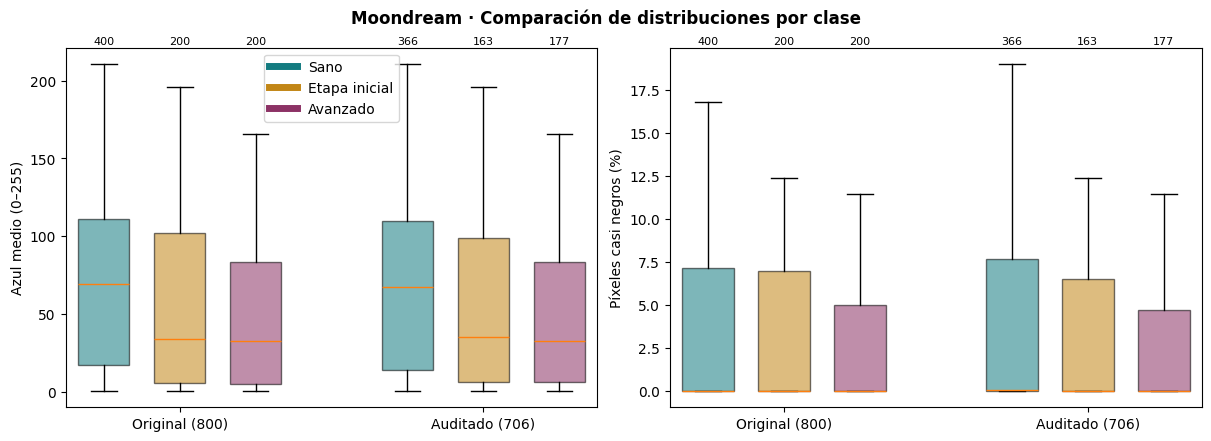

In [3]:
def rgb_y_esquinas(df):
    filas = []
    for p in df["id"]:
        pix = np.asarray(u.leer_rgb(ROOT, p))
        esq = [b.reshape(-1, 3).mean(0) for b in (pix[:4, :4], pix[:4, -4:], pix[-4:, :4], pix[-4:, -4:])]
        r, g, b = pix.mean(axis=(0, 1))
        filas.append({
            "R": r, "G": g, "B": b,
            "pad_negro": int(any(c.max() < 20 for c in esq)),
            "pad_gris": int(any(55 <= c.mean() <= 100 and np.ptp(c) < 8 for c in esq)),
        })
    return pd.concat([df.reset_index(drop=True), pd.DataFrame(filas)], axis=1)

moon_hist = hrows[hrows["coleccion"] == "Moondream Staged"].rename(
    columns={"id_imagen": "id", "etiqueta": "clase", "particion": "split"}
)
moon_hist = moon_hist.merge(rgb_y_esquinas(moon_hist[["id"]]), on="id", how="left")
moon_clean = df_auditado[df_auditado["coleccion"] == "Moondream Staged"][["id", "clase", "split"]].merge(
    moon_hist.drop(columns=["clase", "split"]), on="id", how="left"
)

comp = pd.concat([
    moon_hist.assign(version="Original (800)"),
    moon_clean.assign(version="Auditado (706)"),
], ignore_index=True)

interes = ["R", "G", "B", "brillo_mediano_yn", "negro_pct", "region_pct", "laplaciano_lado512"]
display(comp.groupby(["version", "clase"])[["pad_negro", "pad_gris"]].agg(["size", "mean"]).round(3))
tabla_split = tabla_percentiles(comp, ["version", "split", "clase"], interes)
tabla_split.to_csv(SALIDAS / "03_moondream_por_split.csv", index=False)
display(tabla_split[tabla_split["medida"].isin(["B", "negro_pct"])].round(2))

fig, paneles = plt.subplots(1, 2, figsize=(12, 4.3), layout="constrained")
versiones = comp["version"].unique()
for ax, met, ylab in zip(paneles, ["B", "negro_pct"], ["Azul medio (0–255)", "Píxeles casi negros (%)"]):
    for c_idx, cl in enumerate(u.ENC_3):
        for v_idx, ver in enumerate(versiones):
            vals = comp.loc[(comp["clase"] == cl) & (comp["version"] == ver), met].dropna()
            pos = v_idx * 4 + c_idx
            bp = ax.boxplot(vals, positions=[pos], widths=0.68, patch_artist=True, showfliers=False)
            bp["boxes"][0].set_facecolor(u.COLORES_CLASE[c_idx])
            bp["boxes"][0].set_alpha(0.55)
            ax.text(pos, 1.01, str(len(vals)), transform=ax.get_xaxis_transform(), ha="center", fontsize=8)
    ax.set_xticks(np.arange(len(versiones)) * 4 + 1, versiones)
    ax.set(ylabel=ylab)
paneles[0].legend(handles=[plt.Line2D([0], [0], color=u.COLORES_CLASE[i], lw=5, label=s) for i, s in enumerate(u.CLASES_3)])
fig.suptitle("Moondream · Comparación de distribuciones por clase", fontweight="bold")
plt.show()

## 4. Distribuciones entre fuentes locales

Comparamos las 17 métricas de color, resolución, nitidez y encuadre entre las fuentes disponibles.

,coleccion,medida,n,validos,p25,mediana,p75,RIC
0,ACRIMA,brillo_mediano_yn,703,703,92.00,110.00,126.00,34.00
1,RIM-ONE DL,brillo_mediano_yn,447,447,63.00,85.00,101.00,38.00
2,EyePACS REAL,brillo_mediano_yn,200,199,51.50,77.00,107.00,55.50
3,EyePACS TRAIN,brillo_mediano_yn,93,93,97.00,114.00,123.00,26.00
4,Moondream Staged,brillo_mediano_yn,706,705,65.00,121.00,171.00,106.00
20,ACRIMA,b_media,703,703,12.64,22.72,34.81,22.17
21,RIM-ONE DL,b_media,447,447,20.22,36.18,49.61,29.39
22,EyePACS REAL,b_media,200,199,21.84,42.93,70.25,48.41
23,EyePACS TRAIN,b_media,93,93,18.50,24.58,34.19,15.69
24,Moondream Staged,b_media,706,705,9.59,53.63,101.59,92.01


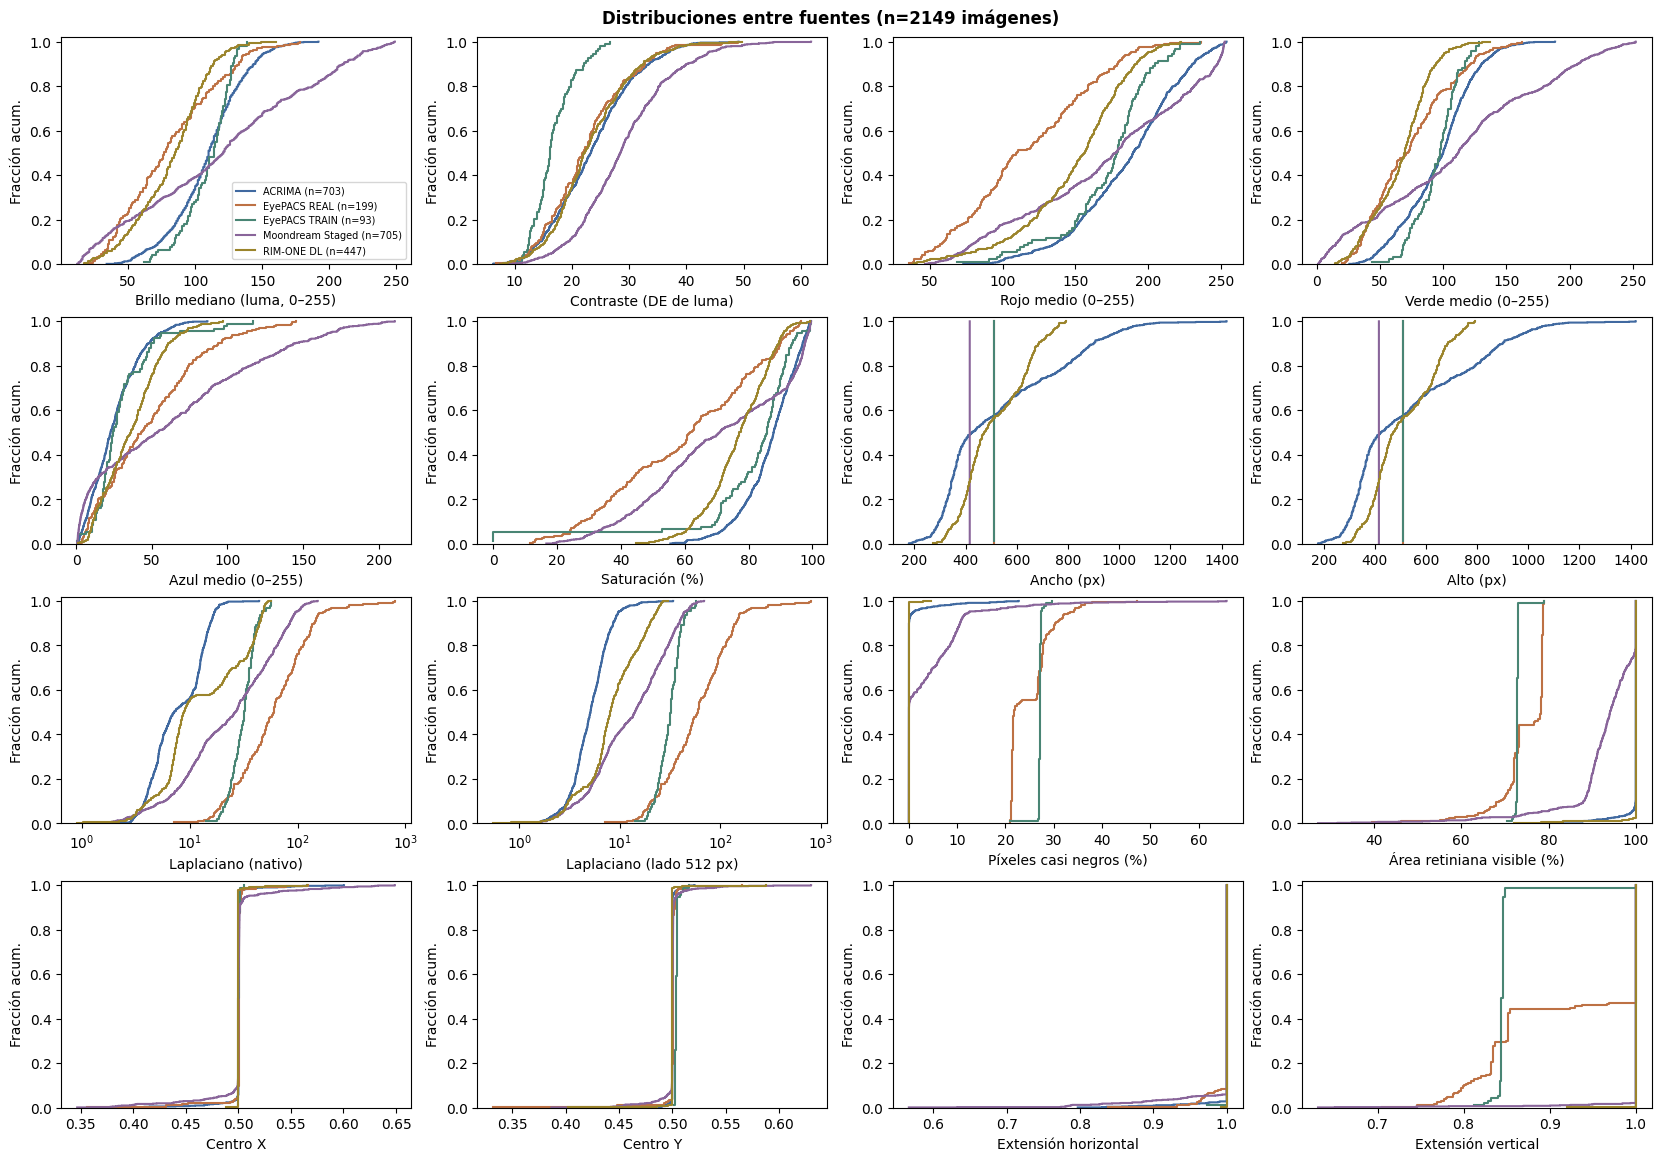

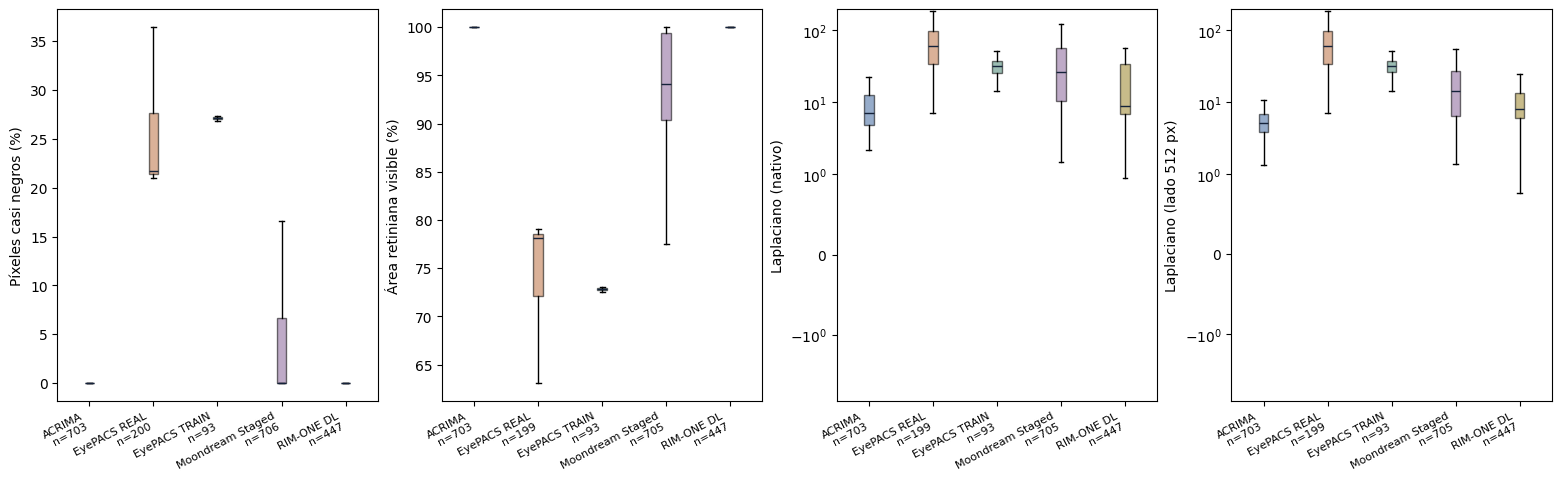

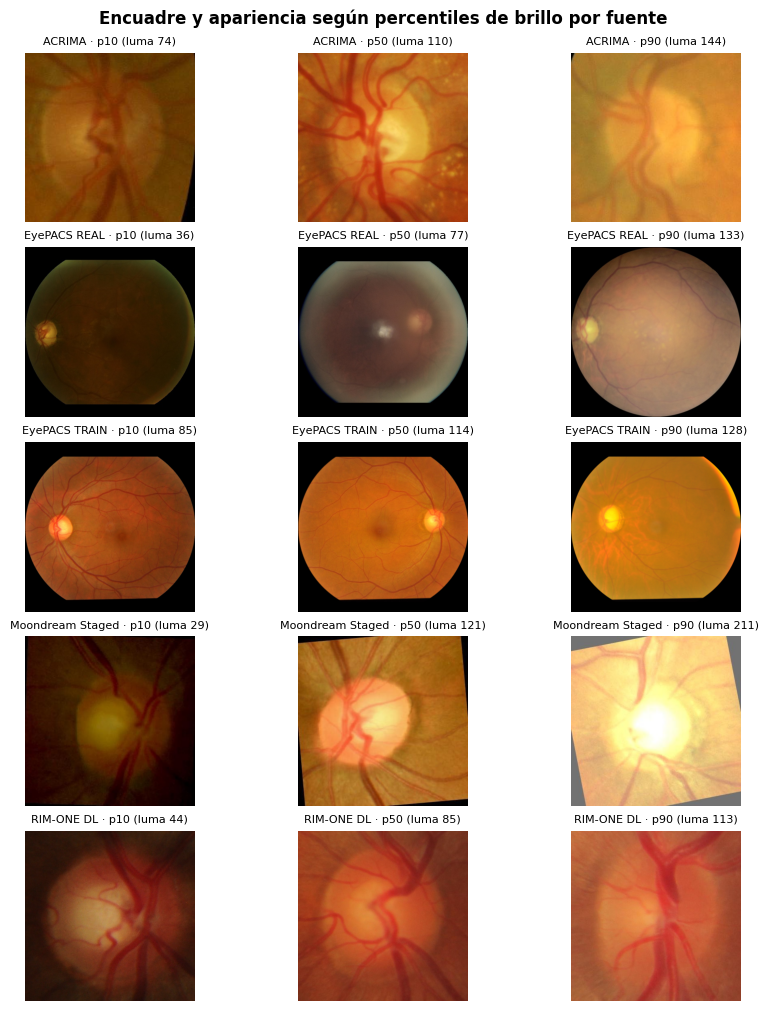

In [4]:
fuentes = hrows[hrows["en_comparacion_fuentes"] == True].copy()
perfil_fuentes = tabla_percentiles(fuentes, ["coleccion"], FEATURES)
perfil_etiquetas = tabla_percentiles(
    hrows[hrows["coleccion"].isin(["Moondream Staged", "ACRIMA", "RIM-ONE DL", "EyePACS REAL", "EyePACS TRAIN"])
          & hrows["en_resumen_grupo"].eq(True) & hrows["conflicto_etiqueta_grupo"].ne(True) & hrows["etiqueta"].notna()],
    ["coleccion", "esquema_etiqueta", "etiqueta"], FEATURES,
)
perfil_fuentes.to_csv(SALIDAS / "03_caracteristicas_por_fuente.csv", index=False)
perfil_etiquetas.to_csv(SALIDAS / "03_caracteristicas_por_etiqueta.csv", index=False)
display(perfil_fuentes[perfil_fuentes["medida"].isin(["brillo_mediano_yn", "b_media", "negro_pct", "region_pct", "laplaciano_lado512"])].round(2))

# Curvas acumuladas (16 métricas)
plots_16 = [k for k in FEATURES if k != "negro_borde_pct"]
fig, axes = plt.subplots(4, 4, figsize=(16.5, 11.5), layout="constrained")
for ax, met in zip(axes.ravel(), plots_16):
    for i, (src, grp) in enumerate(fuentes.groupby("coleccion")):
        vals = np.sort(grp[met].dropna().to_numpy())
        if len(vals):
            ax.step(vals, np.arange(1, len(vals) + 1) / len(vals), color=u.COLORES_FUENTE[i % len(u.COLORES_FUENTE)],
                    where="post", label=f"{src} (n={len(vals)})")
    if met.startswith("laplaciano"):
        ax.set_xscale("symlog", linthresh=1)
    ax.set(xlabel=FEATURES[met], ylabel="Fracción acum.", ylim=(0, 1.02))
axes[0, 0].legend(fontsize=7)
fig.suptitle(f"Distribuciones entre fuentes (n={len(fuentes)} imágenes)", fontweight="bold")
plt.show()

# Boxplots de encuadre y nitidez
foco = ["negro_pct", "region_pct", "laplaciano_nativo", "laplaciano_lado512"]
fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.8), layout="constrained")
for ax, met in zip(axes, foco):
    grupos = list(fuentes.groupby("coleccion"))
    for idx, (src, grp) in enumerate(grupos):
        ax.boxplot(grp[met].dropna(), positions=[idx], patch_artist=True, showfliers=False,
                   boxprops={"facecolor": u.COLORES_FUENTE[idx % len(u.COLORES_FUENTE)], "alpha": 0.55},
                   medianprops={"color": "#14223a"})
    ax.set_xticks(range(len(grupos)), [f"{s}\nn={g[met].count()}" for s, g in grupos], rotation=28, ha="right", fontsize=8)
    if met.startswith("laplaciano"):
        ax.set_yscale("symlog", linthresh=1)
    ax.set(ylabel=FEATURES[met])
plt.show()

# Mosaico por percentiles de brillo (p10, p50, p90)
grupos_f = list(fuentes.groupby("coleccion"))
fig, axes = plt.subplots(len(grupos_f), 3, figsize=(8.2, 2.0 * len(grupos_f)), squeeze=False, layout="constrained")
for (src, grp), fila_ax in zip(grupos_f, axes):
    valid = grp.dropna(subset=["brillo_mediano_yn"]).sort_values(["brillo_mediano_yn", "id_imagen"])
    idxs = np.rint(np.array([0.1, 0.5, 0.9]) * (len(valid) - 1)).astype(int)
    for ax, (_, row), q in zip(fila_ax, valid.iloc[idxs].iterrows(), (10, 50, 90)):
        ax.axis("off")
        if (ROOT / row.id_imagen).is_file():
            ax.imshow(u.leer_rgb(ROOT, row.id_imagen))
        ax.set_title(f"{src} · p{q} (luma {row.brillo_mediano_yn:.0f})", fontsize=8)
fig.suptitle("Encuadre y apariencia según percentiles de brillo por fuente", fontweight="bold")
plt.show()

## 5. Originales frente a derivados (`pares.csv`)

Mediana y rango intercuartílico de la diferencia `derivada − original` para pares verificados entre colecciones.

,fuente,transformacion,medida,n,validos,p25,mediana,p75,RIC
0,ACRIMA,escalar,brillo_mediano_yn,703,703,0.000,0.000,0.000,0.000
1,EyePACS REAL,recortar_color,brillo_mediano_yn,200,199,-3.000,25.000,51.000,54.000
2,Moondream Staged,escalar,brillo_mediano_yn,706,705,0.000,0.000,0.000,0.000
3,RIM-ONE DL,escalar,brillo_mediano_yn,447,447,0.000,0.000,0.000,0.000
4,ACRIMA,emular_web,brillo_mediano_yn,40,40,0.000,0.000,0.000,0.000
5,ACRIMA,escalar,contraste_de_yn,703,703,-0.006,-0.000,0.004,0.009
6,EyePACS REAL,recortar_color,contraste_de_yn,200,199,-6.144,-2.268,1.178,7.321
7,Moondream Staged,escalar,contraste_de_yn,706,705,-0.068,-0.019,-0.005,0.062
8,RIM-ONE DL,escalar,contraste_de_yn,447,447,-0.008,0.001,0.004,0.012
9,ACRIMA,emular_web,contraste_de_yn,40,40,-0.114,-0.079,-0.059,0.055


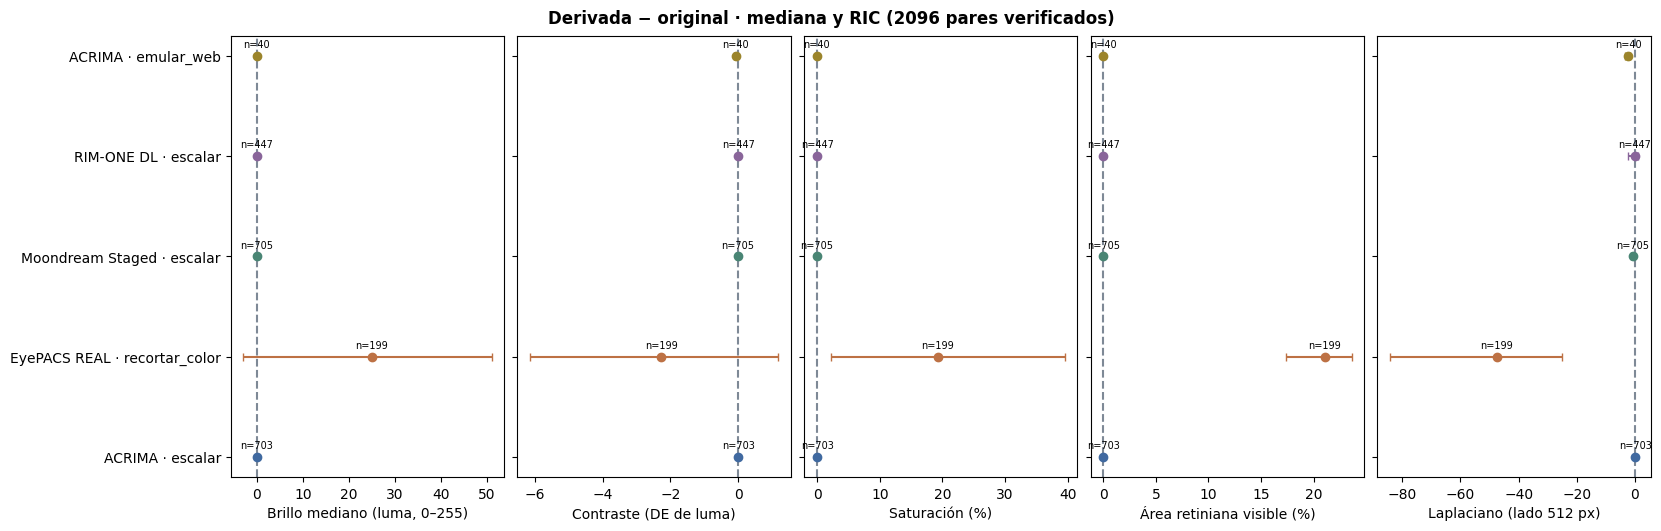

In [5]:
met_pares = ["brillo_mediano_yn", "contraste_de_yn", "saturacion_media_pct", "region_pct", "laplaciano_lado512"]
res_pares = tabla_percentiles(pares, ["fuente", "transformacion"], met_pares)
res_pares.to_csv(SALIDAS / "03_cambios_pareados.csv", index=False)
display(res_pares.round(3))

res_pares["grupo"] = res_pares["fuente"] + " · " + res_pares["transformacion"]
fig, axes = plt.subplots(1, len(met_pares), figsize=(16.5, 5.2), sharey=True, layout="constrained")
for ax, met in zip(axes, met_pares):
    sel = res_pares[res_pares["medida"] == met]
    for i, row in enumerate(sel.itertuples()):
        if row.validos:
            ax.errorbar(row.mediana, i, xerr=[[row.mediana - row.p25], [row.p75 - row.mediana]],
                        fmt="o", color=u.COLORES_FUENTE[i % len(u.COLORES_FUENTE)], capsize=3)
            ax.annotate(f"n={row.validos}", (row.mediana, i), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=7)
    ax.axvline(0, ls="--", color="#7e8996")
    ax.set(xlabel=FEATURES[met], yticks=range(len(sel)), yticklabels=sel["grupo"])
fig.suptitle(f"Derivada − original · mediana y RIC ({len(pares)} pares verificados)", fontweight="bold")
plt.show()

## 6. Limitaciones

- Las comparaciones entre fuentes son descriptivas y reflejan las diferencias de recorte, cámara y preprocesamiento entre bases.
- El área visible estima el campo retiniano útil respecto a bordes negros o rellenos uniformes.